# Fashion Forward: Predicting Product Recommendations

StyleSense’s rapid growth has brought a backlog of reviews with missing recommendation labels. This project uses existing, labeled reviews to build and evaluate a pipeline that predicts product recommendations from review text, customer age, and product information. These predictions could help StyleSense better understand customer satisfaction.

## Instructions for Running this Notebook

You can run this notebook in two different ways:

- From top to bottom to train, tune, and evaluate the models. Training and tuning can take over an hour, depending on hardware and available cache. Runtime can vary.
- Alternatively, recreate visuals without retraining. Run the required imports and chart-style setup. For EDA charts, load the review data, separate features and target, and recreate the train/test split. For evaluation charts, uncomment the optional CSV-loading lines and run the relevant metric and chart cells. Skip model training, search, prediction generation, and cells that assemble results from a live run.

Export commands are commented out to prevent accidental overwriting.

## The Data

The dataset has been anonymized and cleaned of missing values. Each row of data represents a review. Eight input features are used to predict `Recommended IND`.

The features can be summarized as follows:

- **Clothing ID**: Categorical identifier, stored as an integer, for the clothing item reviewed.
- **Age**: Positive integer variable of the reviewer's age.
- **Title**: String variable for the title of the review.
- **Review Text**: String variable for the review body.
- **Positive Feedback Count**: Non-negative integer documenting the number of other customers who found this review positive.
- **Division Name**: Categorical name of the product's high-level division.
- **Department Name**: Categorical name of the product department.
- **Class Name**: Categorical name of the product class.

The target:
- **Recommended IND**: Binary indicator of whether the customer recommends the product: 1 = recommended; 0 = not recommended.

## Load Data

In [2]:
# Load data

import pandas as pd

df = pd.read_csv('data/reviews.csv')

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 18442 entries, 0 to 18441
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              18442 non-null  int64
 1   Age                      18442 non-null  int64
 2   Title                    18442 non-null  str  
 3   Review Text              18442 non-null  str  
 4   Positive Feedback Count  18442 non-null  int64
 5   Division Name            18442 non-null  str  
 6   Department Name          18442 non-null  str  
 7   Class Name               18442 non-null  str  
 8   Recommended IND          18442 non-null  int64
dtypes: int64(4), str(5)
memory usage: 1.3 MB


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name,Recommended IND
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses,0
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants,1
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses,1
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses,0
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits,1


## Preparing features (`X`) & target (`y`)

In [3]:
# Separate features from labels

X = df.drop('Recommended IND', axis=1)
y = df['Recommended IND'].copy()

print('Labels:', y.unique())
print('Features:')
display(X.head())

Labels: [0 1]
Features:


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits


In [4]:
# Split data into train and test sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    shuffle=True,
    stratify=y,
    random_state=27,
)

With over 18,000 reviews, a 90/10 train/test split was used, with a fixed random seed for reproducibility. Stratification by the target variable preserved approximately the same recommendation-class proportions in both sets.

## Data Exploration

Exploratory data analysis (EDA) uses the training set to examine reviewer age distribution, recommendation class balance, review concentration across products, and the lengths of reviews.

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from matplotlib import font_manager

font_files = font_manager.findSystemFonts(fontpaths=['../fonts'])

for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

plt.style.use('my_charts.mplstyle')

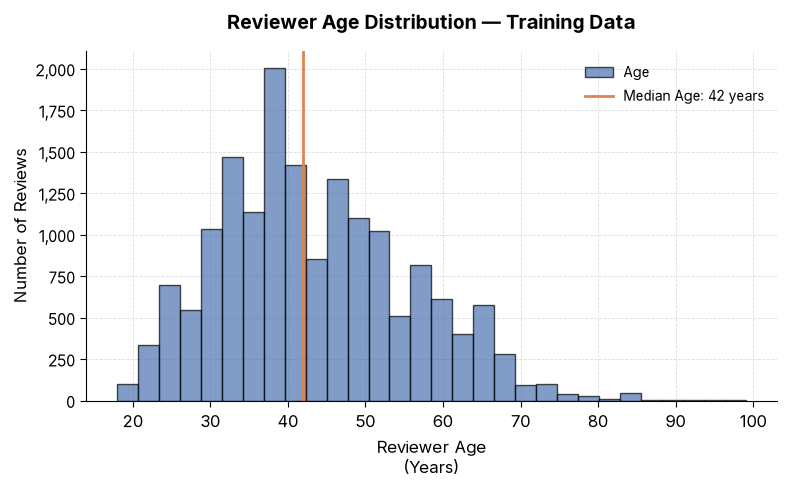

In [6]:
# Examine the distribution of reviewer ages

ax = X_train['Age'].plot(kind="hist", bins=30, alpha=0.7)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

median_age = X_train['Age'].median()

plt.axvline(
    median_age,
    color='C1',
    linewidth=2.0,
    alpha=1.0,
    label=f'Median Age: {median_age:g} years',
)

plt.legend()
plt.xlabel("Reviewer Age\n(Years)")
plt.ylabel("Number of Reviews")
plt.title("Reviewer Age Distribution — Training Data")
plt.show()

The reviews represent a broad range of ages, with a median reviewer age of 42. StyleSense’s description as offering “trendy and affordable fashion” prompted an initial expectation of younger reviewers, which the distribution does not support. However, reviewers may not represent the retailer’s entire customer base.

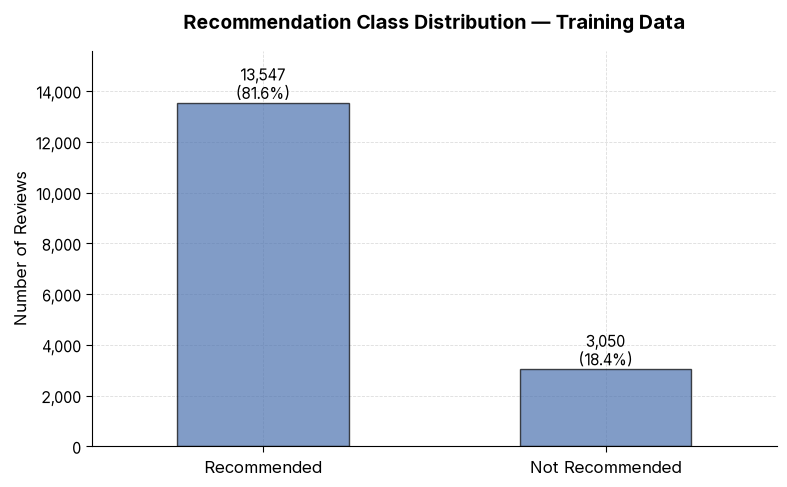

In [7]:
# Check to see if y_train is balanced

counts = y_train.value_counts()
percentages = y_train.value_counts(normalize=True).mul(100)

ax = counts.plot(kind="bar", alpha=0.7)

labels = [f"{c:,}\n({p:.1f}%)" for c, p in zip(counts, percentages)]

ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax.set_ylim(top=max(counts) * 1.15)
ax.bar_label(ax.containers[0], labels=labels)

plt.xlabel('')
plt.xticks([0, 1], ['Recommended', 'Not Recommended'], rotation=0)
plt.ylabel("Number of Reviews")
plt.title("Recommendation Class Distribution — Training Data")

plt.show()

The target variable is imbalanced: over 80% of reviews indicate that the customer recommends the product. I therefore stratified the train/test split by the target to preserve approximately the same class proportions in both sets. I evaluated performance using accuracy and macro F1-score, which gives both classes equal weight, and used macro F1-score to select the best model during hyperparameter tuning.

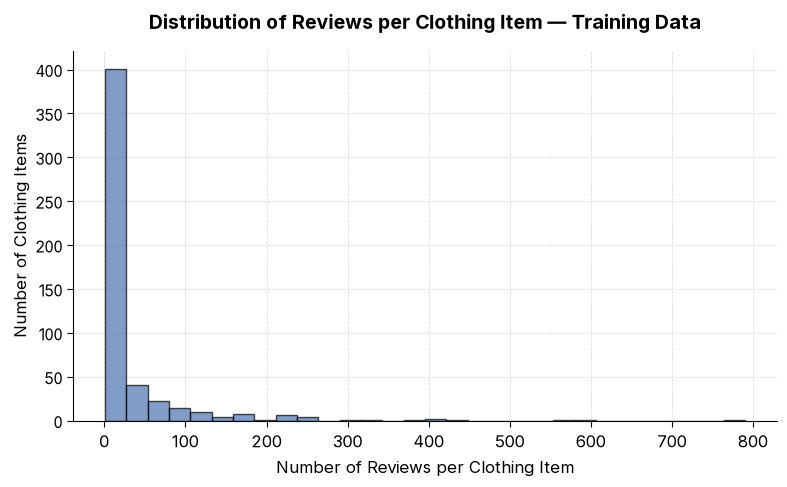

In [8]:
# Reviews per clothing item

X_train['Clothing ID'].value_counts().plot(kind="hist", bins=30, alpha=0.7)

plt.xlabel("Number of Reviews per Clothing Item")
plt.ylabel("Number of Clothing Items")
plt.title("Distribution of Reviews per Clothing Item — Training Data")
plt.show()

In [9]:
# Reviews (%) of top 10 clothing items

top_10_reviews_sum = X_train['Clothing ID'].value_counts().head(10).sum()
top_10_percentage = (top_10_reviews_sum / len(X_train)) * 100

print(
    f"Top 10 items account for {top_10_percentage:.2f}% "
    "of all reviews in the training set."
)

Top 10 items account for 27.08% of all reviews in the training set.


Reviews are highly concentrated among a relatively small number of clothing items: the top 10 account for more than one quarter of all reviews in the training set. This provides less evidence for learning item-specific patterns for rarely reviewed products, although the classifier can still draw on patterns shared across products.

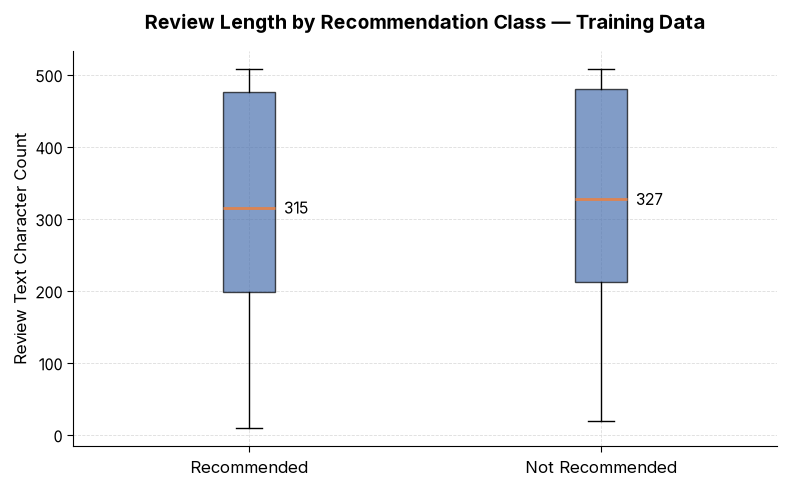

In [10]:
# Review Text character count by recommendation

clean_series = X_train['Review Text'].fillna('').astype(str)
char_counts = clean_series.str.len()

not_rec = char_counts[y_train == 0]
rec = char_counts[y_train == 1]

plt.boxplot(
    [rec, not_rec],
    patch_artist=True,
    medianprops={'linewidth': 2.0, 'alpha': 1.0},
    boxprops={
        'facecolor': plt.rcParams['axes.prop_cycle'].by_key()['color'][0],
        'edgecolor': 'black',
        'alpha': 0.7,
    },
)


for position, values in enumerate([rec, not_rec], start=1):
    median = np.median(values)
    plt.text(
        position + 0.1,
        median,
        f'{median:,.0f}',
        ha='left',
        va='center',
    )

plt.xticks([1, 2], ['Recommended', 'Not Recommended'])
plt.ylabel("Review Text Character Count")
plt.title("Review Length by Recommendation Class — Training Data")
plt.show()

Review lengths are similar across recommendation classes, with only a small difference in median character count and substantial overlap in their distributions. Character count alone therefore appears unlikely to distinguish the classes well.

## Building the Pipeline

Numerical and categorical features are preprocessed separately. Title and Review Text, the only two text features, are concatenated, lemmatized, and converted to TF-IDF features. A character count of the original Review Text is added as an engineered feature. The preprocessing branches are then combined for use by the classifier.

In [11]:
# Categorize features into the three relevant groups

num_features = ['Age', 'Positive Feedback Count']

cat_features = [
    'Clothing ID',
    'Division Name',
    'Department Name',
    'Class Name',
]

text_features = ['Title', 'Review Text']

print('Numerical features:', num_features)
print('Categorical features:', cat_features)
print('Text features:', text_features)

Numerical features: ['Age', 'Positive Feedback Count']
Categorical features: ['Clothing ID', 'Division Name', 'Department Name', 'Class Name']
Text features: ['Title', 'Review Text']


The data contain 2 numerical, 4 categorical and 2 text features.

In [12]:
# Define pipeline for numerical features

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
])

num_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for 

Missing numerical values are replaced with training-set means. Numerical inputs are standardized, although this is not necessary for a Random Forest Classifier.

In [13]:
# Define pipeline for categorical features

from sklearn.preprocessing import OneHotEncoder

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    (
        'cat_encoder',
        OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
    ),
])

cat_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('cat_encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatort

Missing categorical values are replaced with the most frequent category learned from the training data. Categorical features are one-hot encoded; unseen categories are represented by zeros in that feature’s encoded columns during prediction.

In [14]:
# Create a function to count the number of characters in a review


def review_text_char_count(
    df: pd.DataFrame, col_name: str = 'Review Text'
) -> np.ndarray:

    clean_series = df[col_name].fillna('').astype(str)
    char_counts = clean_series.str.len()

    return char_counts.to_numpy().reshape(-1, 1)

In [15]:
# Test the function

train_df = pd.DataFrame({
    'Review Text': ["Loved every minute of using it.", None, "Great product!"],
})

char_count_matrix = review_text_char_count(train_df, col_name='Review Text')

print("Output Type:", type(char_count_matrix))
print("Output Shape:", char_count_matrix.shape)
print("\n2D Array Output:\n", char_count_matrix)

Output Type: <class 'numpy.ndarray'>
Output Shape: (3, 1)

2D Array Output:
 [[31]
 [ 0]
 [14]]


In [16]:
# Combine Title and Review Text for the text pipeline


def combine_title_and_review(df: pd.DataFrame) -> pd.Series:

    return df['Title'].fillna('') + " " + df['Review Text'].fillna('')

In [17]:
# Tokenize, lemmatize in batches

import spacy

nlp = spacy.load("en_core_web_sm")


def preprocess_reviews_batched(
    reviews: pd.Series, batch_size: int = 64
) -> pd.Series:

    processed_texts = []

    for doc in nlp.pipe(reviews.astype(str), batch_size=batch_size):
        tokens = [
            token.lemma_.lower()
            for token in doc
            if not token.is_punct and not token.is_space
        ]
        processed_texts.append(" ".join(tokens))

    return pd.Series(processed_texts, index=reviews.index)

Text processing lowercases lemmas and removes punctuation and whitespace tokens while retaining stop words, including negation words.

In [18]:
# Test tokenization / lemmatization

print(preprocess_reviews_batched(pd.Series([
    'I am the president of the United States',
    'We load two categories from the training set'
])))

0       i be the president of the united states
1    we load two category from the training set
dtype: str


In [19]:
# Create pipeline for text preparation workflow

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer

tfidf_pipeline = Pipeline([
    (
        'combine_columns',
        FunctionTransformer(combine_title_and_review, validate=False),
    ),
    (
        'preprocess_reviews',
        FunctionTransformer(preprocess_reviews_batched, validate=False),
    ),
    ('vectorizer', TfidfVectorizer()),
])

tfidf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('combine_columns', ...), ('preprocess_reviews', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function com...00253270CDA80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, de

FunctionTransformer wraps our preprocessing functions so they can be used as steps in our pipeline.


In [20]:
# Consolidate preprocessing in a single pipeline

from sklearn.compose import ColumnTransformer

feature_engineering = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features),
    (
        'character_counts',
        FunctionTransformer(review_text_char_count, validate=False),
        ['Review Text'],
    ),
    ('tfidf_text', tfidf_pipeline, text_features),
])

feature_engineering

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [20]:
# Examine the shape of the transformed X_train

train_spot = feature_engineering.fit_transform(X_train)
train_spot.shape

(16597, 11277)

Preprocessing expands the eight original input features into 11,277 numerical features through one-hot encoding, TF-IDF vectorization, and the addition of review character count. The number of training observations remains unchanged at 16,597.

## Training the Pipeline

Random Forest was selected as the classifier because it can capture nonlinear relationships and interactions between features. It also provided a familiar baseline from the lesson. Caching was used to reuse preprocessing results when inputs and settings matched, reducing repeated computation during tuning.

In [ ]:
# Assemble pipeline into a single workflow

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

model_pipeline = make_pipeline(
    feature_engineering,
    RandomForestClassifier(random_state=27),
    memory='pipeline_cache',
)

model_pipeline.fit(X_train, y_train)

## Evaluating the Pipeline

Performance was evaluated on the held-out test set using accuracy, per-class precision, and macro F1. Accuracy measures the overall proportion of correct predictions; per-class precision measures how often predictions of each class are correct. Macro F1 gives equal weight to both classes, making weak performance on the less frequent “Not recommended” class more visible.

In [22]:
# Baseline parameter values

baseline_rfc = model_pipeline.named_steps['randomforestclassifier']

display(
    pd.Series(baseline_rfc.get_params(), name='Baseline Value')
    .rename_axis('Parameter')
    .to_frame()
)

,Baseline Value
Parameter,
bootstrap,True
ccp_alpha,0.0
class_weight,None
criterion,gini
max_depth,None
max_features,sqrt
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0


In [23]:
# Get the predicted class label, accuracy and precision scores

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

y_pred = model_pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision_rec = precision_score(y_test, y_pred)
precision_not_rec = precision_score(y_test, y_pred, pos_label=0)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision - Recommended Class: {precision_rec:.4f}")
print(f"Precision - Not Recommended Class: {precision_not_rec:.4f}")

Accuracy: 0.8374
Precision - Recommended Class: 0.8361
Precision - Not Recommended Class: 0.8824


In [24]:
# Get the confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cm_table = pd.DataFrame(
    cm,
    index=['Actual: Not recommended', 'Actual: Recommended'],
    columns=['Predicted: Not recommended', 'Predicted: Recommended'],
)

display(cm_table)

,Predicted: Not recommended,Predicted: Recommended
Actual: Not recommended,45,294
Actual: Recommended,6,1500


In [25]:
# Get macro F1

from sklearn.metrics import f1_score

macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"Macro F1 Score: {macro_f1:.4f}")

Macro F1 Score: 0.5699


The baseline model achieved an accuracy of 0.8374 and a macro F1-score of 0.5699. Precision was 0.8361 for the Recommended class and 0.8824 for the Not Recommended class. Although its not-recommended predictions were usually correct, the model identified only 45 of 339 actual not-recommended reviews—a recall of 13.3%. This weak minority-class recall explains the low macro F1-score despite relatively high accuracy and precision.

For comparison, always predicting “Recommended” would achieve a test accuracy of 0.8163. The baseline model improves on this by only 2.1 percentage points, highlighting why accuracy alone is insufficient for evaluating this imbalanced dataset.

## Fine-Tuning Pipeline

In [26]:
# Set parameters to randomly search over

from sklearn.model_selection import RandomizedSearchCV

my_distributions = dict(
    randomforestclassifier__max_features=[100, 250],
    randomforestclassifier__n_estimators=[150, 300],
)

param_search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=my_distributions,
    n_iter=4,
    scoring="f1_macro",
    cv=3,
    n_jobs=1,
    error_score='raise',
    refit=True,
    verbose=3,
    random_state=27,
)

param_search.fit(X_train, y_train)

# Retrieve the best parameters
print(f"Best parameters: {param_search.best_params_}")
print(f"Best score: {param_search.best_score_}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV 1/3] END randomforestclassifier__max_features=100, randomforestclassifier__n_estimators=150;, score=0.586 total time= 3.5min
[CV 2/3] END randomforestclassifier__max_features=100, randomforestclassifier__n_estimators=150;, score=0.578 total time= 3.5min
[CV 3/3] END randomforestclassifier__max_features=100, randomforestclassifier__n_estimators=150;, score=0.558 total time= 3.6min
[CV 1/3] END randomforestclassifier__max_features=100, randomforestclassifier__n_estimators=300;, score=0.581 total time= 1.5min
[CV 2/3] END randomforestclassifier__max_features=100, randomforestclassifier__n_estimators=300;, score=0.571 total time= 1.5min
[CV 3/3] END randomforestclassifier__max_features=100, randomforestclassifier__n_estimators=300;, score=0.559 total time= 1.5min
[CV 1/3] END randomforestclassifier__max_features=250, randomforestclassifier__n_estimators=150;, score=0.665 total time= 1.4min
[CV 2/3] END randomforestclassifier__

In [27]:
# Obtain best estimator from the completed search

model_best = param_search.best_estimator_

# Alternatively, load the saved estimator

# import joblib
# model_best = joblib.load('best_model.joblib')

model_best


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'pipeline_cache'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Clothing ID','Age','Title',...,'Division Name','Department Name', 'Class Name']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).

In [28]:
# Tuned parameter values

tuned_rfc = model_best.named_steps['randomforestclassifier']

display(
    pd.Series(tuned_rfc.get_params(), name='Tuned Value')
    .rename_axis('Parameter')
    .to_frame()
)

,Tuned Value
Parameter,
bootstrap,True
ccp_alpha,0.0
class_weight,None
criterion,gini
max_depth,None
max_features,250
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0


In [29]:
# Get the predicted class label, accuracy and precision scores

y_pred_opt = model_best.predict(X_test)
accuracy_opt = accuracy_score(y_test, y_pred_opt)
precision_opt_rec = precision_score(y_test, y_pred_opt)
precision_opt_not_rec = precision_score(y_test, y_pred_opt, pos_label=0)

print(f"Accuracy: {accuracy_opt:.4f}")
print(f"Precision - Recommended Class: {precision_opt_rec:.4f}")
print(f"Precision - Not Recommended Class: {precision_opt_not_rec:.4f}")

Accuracy: 0.8596
Precision - Recommended Class: 0.8581
Precision - Not Recommended Class: 0.8846


In [30]:
# Get the confusion matrix

cm_opt = confusion_matrix(y_test, y_pred_opt, labels=[0, 1])

cm_table_opt = pd.DataFrame(
    cm_opt,
    index=['Actual: Not recommended', 'Actual: Recommended'],
    columns=['Predicted: Not recommended', 'Predicted: Recommended'],
)

display(cm_table_opt)

,Predicted: Not recommended,Predicted: Recommended
Actual: Not recommended,92,247
Actual: Recommended,12,1494


In [31]:
# Get macro F1

macro_f1_opt = f1_score(y_test, y_pred_opt, average='macro')

print(f"Macro F1 Score: {macro_f1_opt:.4f}")

Macro F1 Score: 0.6678


The tuned model achieved an accuracy of 0.8596 and a macro F1-score of 0.6678. Precision was 0.8581 for the Recommended class and 0.8846 for the Not Recommended class. It correctly identified 92 of 339 not-recommended reviews, compared with 45 for the baseline, while maintaining similar precision for that class. Even so, it still missed 72.9% of not-recommended reviews, indicating that detection of this class remains a significant limitation.

In [32]:
# Prepare search results for evaluation

search_results_df = pd.DataFrame(param_search.cv_results_)

# search_results_df.to_csv('cv_results.csv', index=False)

In [33]:
# Optional: load saved search results instead of running the search
# search_results_df = pd.read_csv('cv_results.csv')

search_results_df.info()
search_results_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 13 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   mean_fit_time                               4 non-null      float64
 1   std_fit_time                                4 non-null      float64
 2   mean_score_time                             4 non-null      float64
 3   std_score_time                              4 non-null      float64
 4   param_randomforestclassifier__n_estimators  4 non-null      int64  
 5   param_randomforestclassifier__max_features  4 non-null      int64  
 6   params                                      4 non-null      object 
 7   split0_test_score                           4 non-null      float64
 8   split1_test_score                           4 non-null      float64
 9   split2_test_score                           4 non-null      float64
 10  mean_test_score              

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_randomforestclassifier__n_estimators,param_randomforestclassifier__max_features,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,144.019209,0.852695,69.048967,0.728645,150,100,"{'randomforestclassifier__n_estimators': 150, ...",0.586194,0.578338,0.558356,0.574296,0.011719,3
1,17.388307,0.103801,70.182178,0.274481,300,100,"{'randomforestclassifier__n_estimators': 300, ...",0.581199,0.571448,0.559087,0.570578,0.009048,4
2,13.886877,0.198771,68.925175,0.143124,150,250,"{'randomforestclassifier__n_estimators': 150, ...",0.664791,0.673684,0.669486,0.669320,0.003633,1
3,27.257040,0.266222,69.957298,0.236104,300,250,"{'randomforestclassifier__n_estimators': 300, ...",0.665000,0.674338,0.665426,0.668255,0.004305,2


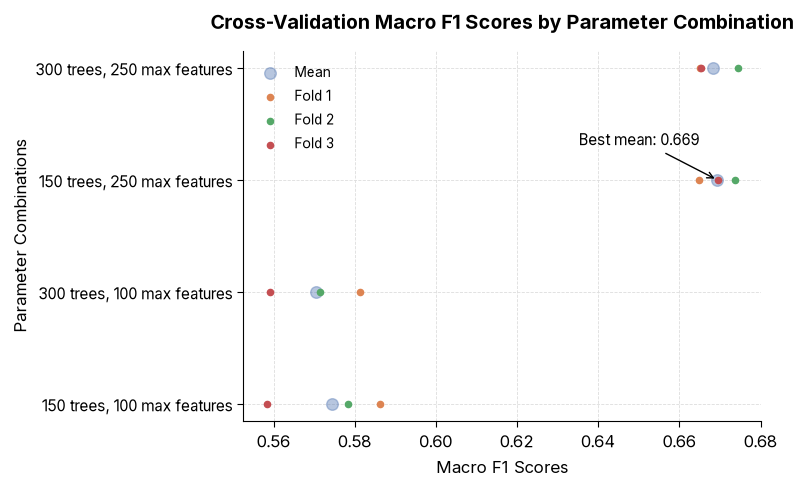

In [34]:
# Dot plot of CV macro F1 by parameter combination

vertax = [0, 1, 2, 3]

plt.scatter(
    search_results_df['mean_test_score'], vertax,
    s=70, label='Mean', alpha=0.4,
)


fold_columns = ['split0_test_score', 'split1_test_score', 'split2_test_score']
for fold, column in enumerate(fold_columns, start=1):
    plt.scatter(
        search_results_df[column], vertax,
        s=20, label=f'Fold {fold}', alpha=1.0,
    )

plt.legend()
plt.xlabel("Macro F1 Scores")
plt.yticks(vertax, [
    '150 trees, 100 max features',
    '300 trees, 100 max features',
    '150 trees, 250 max features',
    '300 trees, 250 max features',
])
plt.ylabel("Parameter Combinations")
plt.title("Cross-Validation Macro F1 Scores by Parameter Combination")

best_position = search_results_df['mean_test_score'].to_numpy().argmax()
best_score = search_results_df['mean_test_score'].iloc[best_position]

plt.annotate(
    f'Best mean: {best_score:.3f}',
    xy=(best_score, vertax[best_position]),
    xytext=(-100, 25),
    textcoords='offset points',
    arrowprops={'arrowstyle': '->'},
)

plt.show()

Macro F1 is used to guide selection, because it gives both recommendation classes equal weight.

Across the four parameter combinations evaluated using three-fold cross-validation, increasing max_features from 100 to 250 improved mean macro F1 from approximately 0.57 to 0.67. Increasing the number of trees from 150 to 300 provided no improvement within this search. The selected configuration used 150 trees and 250 candidate features per split, achieving a mean cross-validation macro F1 of 0.6693.

In [35]:
# Save the best model
# import joblib
# joblib.dump(model_best, 'best_model.joblib')

In [36]:
# Prepare predictions for evaluation visuals

comparison_df = pd.DataFrame({
    'y_test': y_test,
    'y_pred': y_pred,
    'y_pred_opt': y_pred_opt,
})

# comparison_df.to_csv(
#     'model_predictions_comparison.csv',
#     index=True,
#     index_label='original_row_index',
# )

In [37]:
# Load data for model prediction comparison plot
# comparison_df = pd.read_csv('model_predictions_comparison.csv')

comparison_df.info()
comparison_df.head()

<class 'pandas.DataFrame'>
Index: 1845 entries, 4218 to 15524
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   y_test      1845 non-null   int64
 1   y_pred      1845 non-null   int64
 2   y_pred_opt  1845 non-null   int64
dtypes: int64(3)
memory usage: 57.7 KB


,y_test,y_pred,y_pred_opt
4218,1,1,1
7107,1,1,1
12227,0,1,1
1089,0,1,1
12541,0,1,1


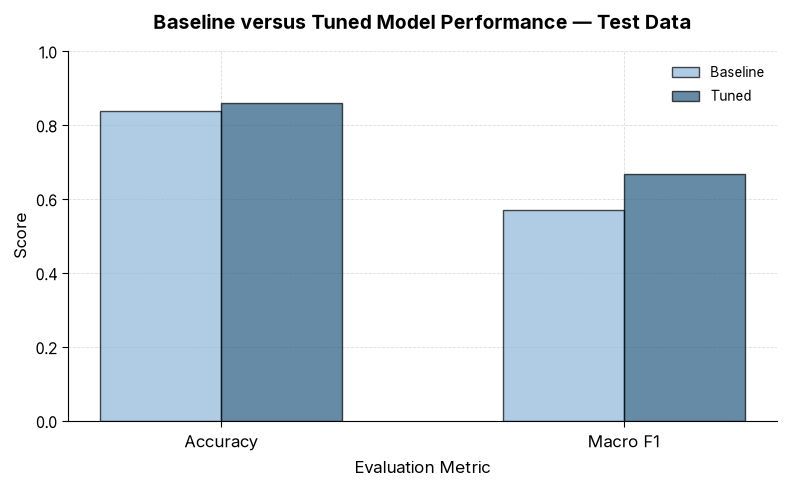

In [38]:
# Plot of baseline versus tuned test performance

acc_base = accuracy_score(comparison_df['y_test'], comparison_df['y_pred'])
mac_f1_base = f1_score(
    comparison_df['y_test'], comparison_df['y_pred'], average='macro'
)

acc_opt = accuracy_score(comparison_df['y_test'], comparison_df['y_pred_opt'])
mac_f1_opt = f1_score(
    comparison_df['y_test'], comparison_df['y_pred_opt'], average='macro'
)

# Categories: metrics
categories = ['Accuracy', 'Macro F1']

# Groups: models
baseline = [acc_base, mac_f1_base]
tuned = [acc_opt, mac_f1_opt]

x = np.arange(len(categories))
width = 0.3

plt.bar(
    x - width / 2, baseline, width,
    label='Baseline', color='#8FB6D9', alpha=0.7,
)
plt.bar(
    x + width / 2, tuned, width,
    label='Tuned', color='#245A81', alpha=0.7,
)

plt.xticks(x, categories)
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.title("Baseline versus Tuned Model Performance — Test Data")

plt.show()

The tuned model improved both accuracy and macro F1, with a larger gain in macro F1. It identified more not-recommended reviews while maintaining high recall for recommended reviews, although detection of the minority class remained limited.

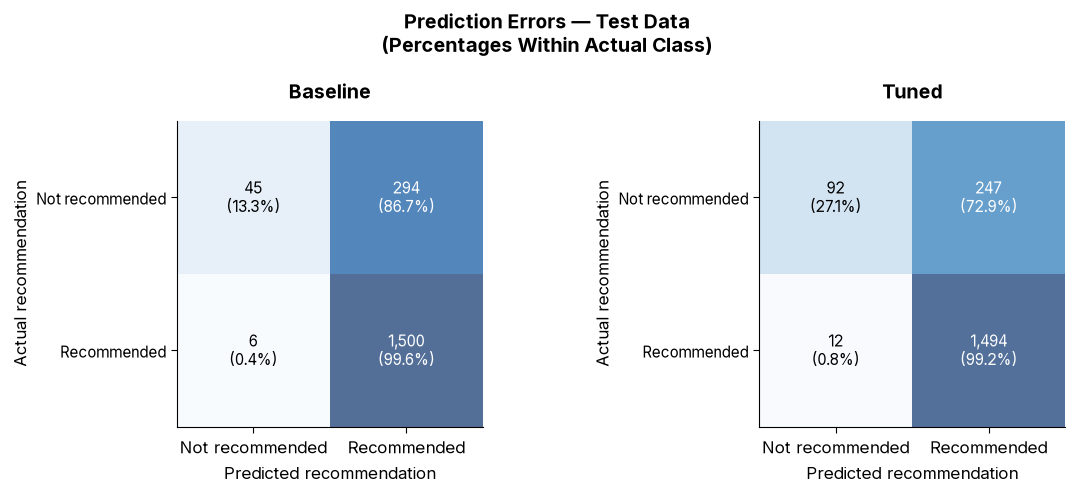

In [39]:
# Plot the confusion matrices

from sklearn.metrics import ConfusionMatrixDisplay


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, prediction_column, title in zip(
    axes,
    ['y_pred', 'y_pred_opt'],
    ['Baseline', 'Tuned'],
):
    counts = confusion_matrix(
        comparison_df['y_test'],
        comparison_df[prediction_column],
        labels=[0, 1],
    )
    proportions = counts / counts.sum(axis=1, keepdims=True)

    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=proportions,
        display_labels=['Not recommended', 'Recommended'],
    )
    cm_display.plot(
        ax=ax,
        include_values=False,
        cmap='Blues',
        colorbar=False,
        im_kw={'vmin': 0, 'vmax': 1, 'alpha': 0.7},
    )

    for row in range(2):
        for col in range(2):
            ax.text(
                col,
                row,
                f'{counts[row, col]:,}\n({proportions[row, col]:.1%})',
                ha='center',
                va='center',
                color='white' if proportions[row, col] > 0.5 else 'black',
            )

    ax.set_title(title)
    ax.set_xlabel('Predicted recommendation')
    ax.set_ylabel('Actual recommendation')
    ax.grid(False)

fig.suptitle(
    'Prediction Errors — Test Data\n(Percentages Within Actual Class)'
)
plt.show()

Tuning increased recall for not-recommended reviews from 13.3% to 27.1%, identifying 47 additional cases. This came at the cost of misclassifying six additional recommended reviews. Despite the improvement, the model still missed 72.9% of not-recommended reviews and remained strongly biased toward predicting a recommendation.